In [1]:
import pandas as pd
from itertools import combinations
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Biểu đồ đã được lưu vào tệp 'sentiment_distribution.png'


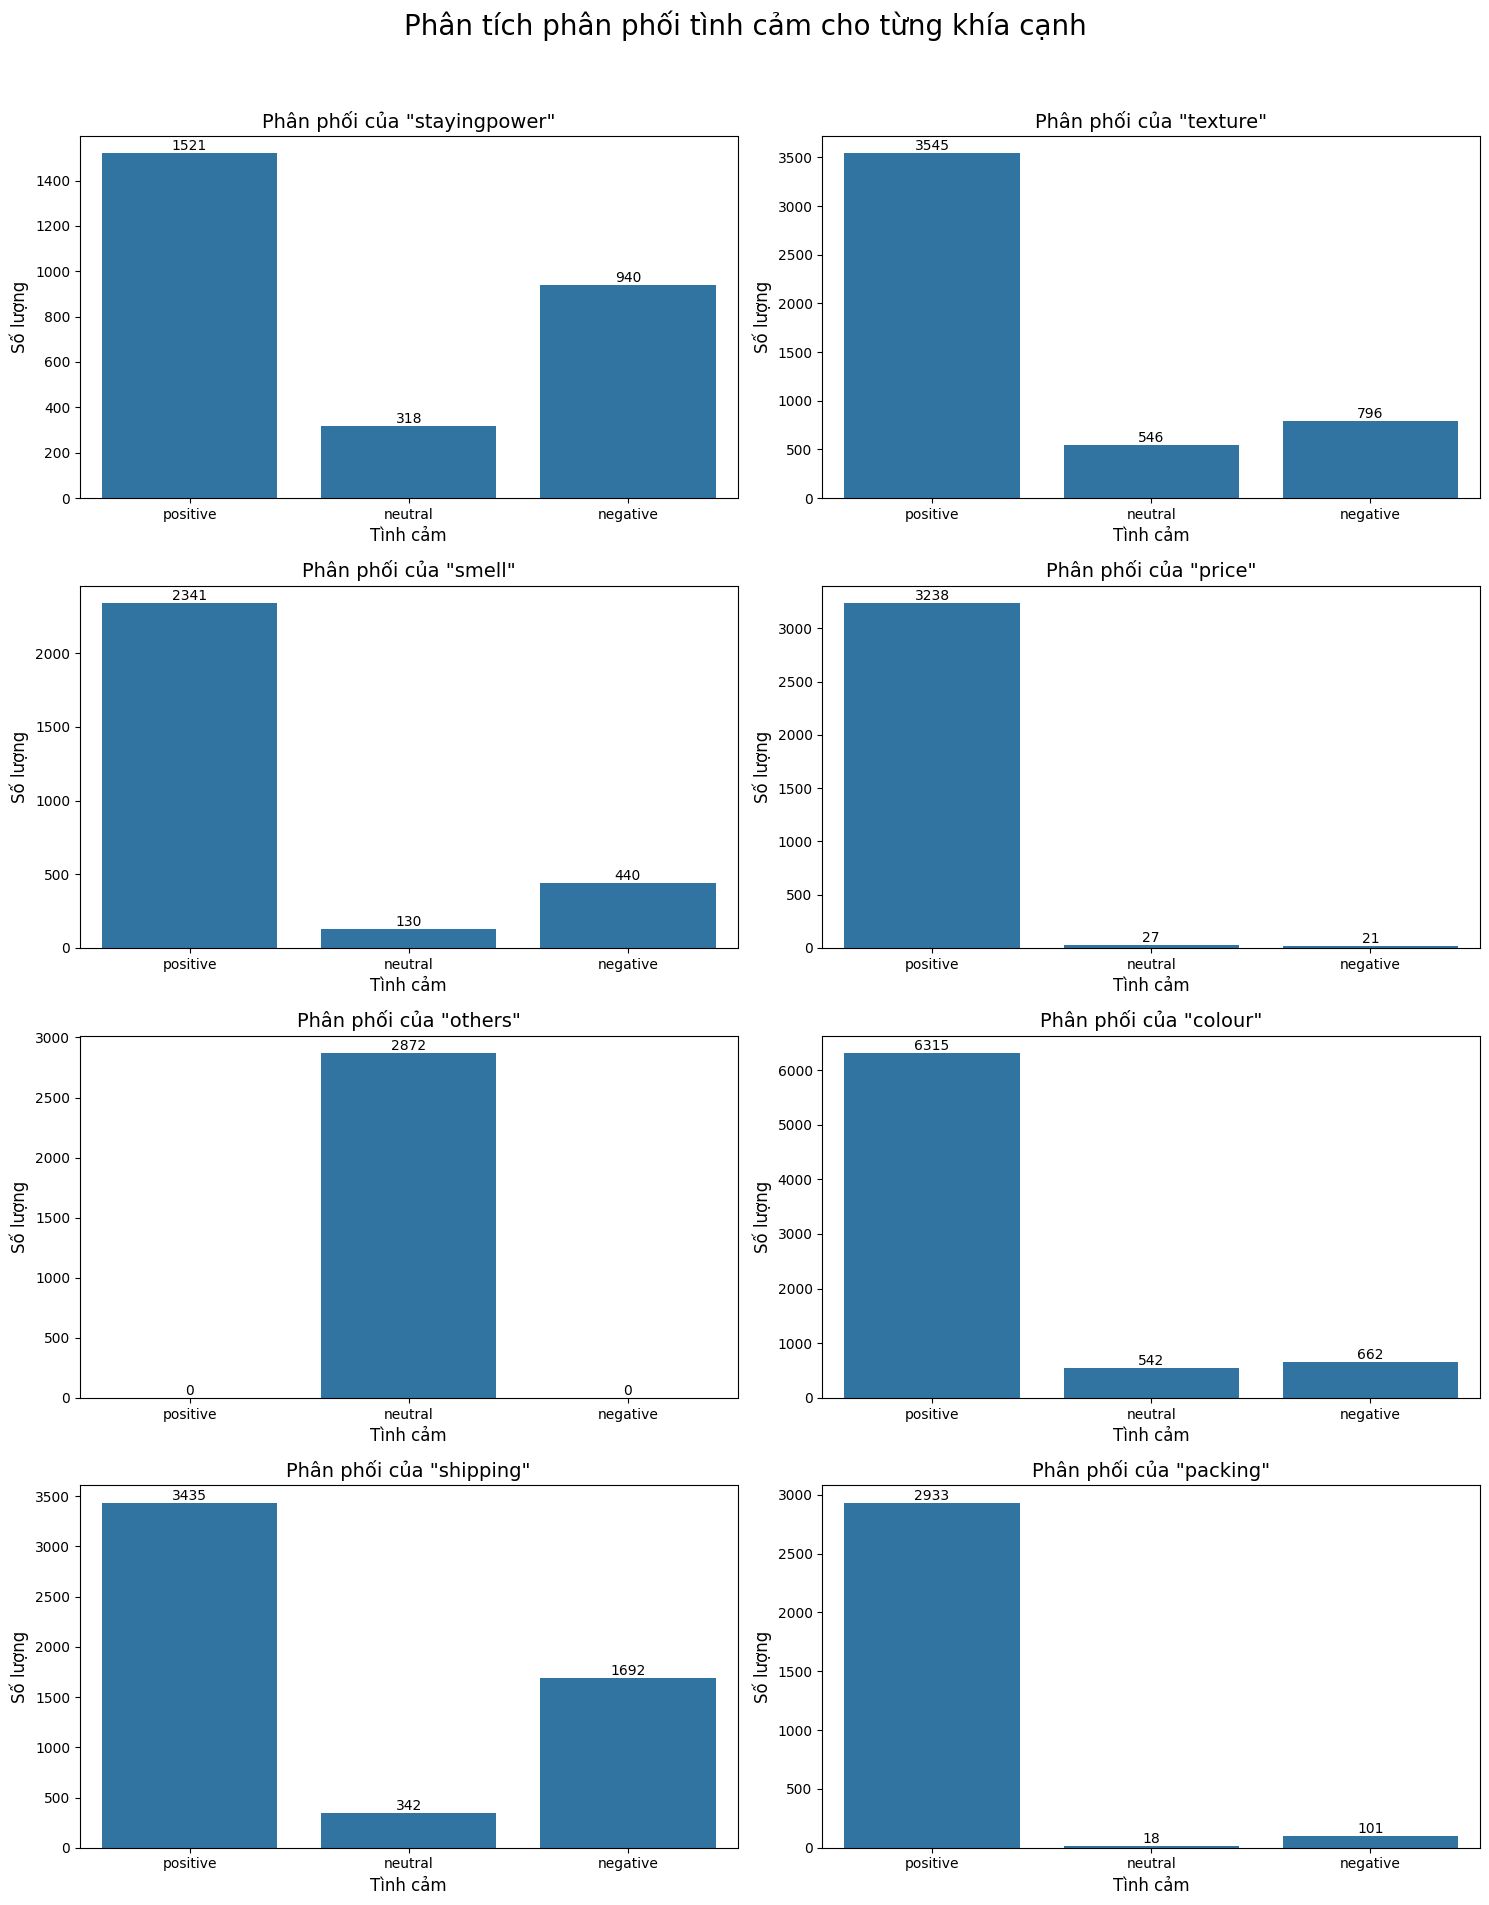

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tải bộ dữ liệu đầy đủ
df_full = pd.read_csv('/content/drive/MyDrive/XlNNTN (TH)/full_data.csv')

# Danh sách các cột khía cạnh cần phân tích
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']

# --- Đếm số lượng tình cảm cho mỗi khía cạnh ---
sentiment_counts = {}
for col in aspect_columns:
    # Đếm số lần xuất hiện của mỗi giá trị (positive, neutral, negative)
    sentiment_counts[col] = df_full[col].value_counts()

# --- Trực quan hóa dữ liệu ---
# Tạo một figure lớn chứa 8 biểu đồ nhỏ (4 hàng, 2 cột)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
fig.suptitle('Phân tích phân phối tình cảm cho từng khía cạnh', fontsize=20)

# Làm phẳng mảng axes để dễ dàng lặp qua
axes = axes.flatten()

# Vẽ biểu đồ cột cho từng khía cạnh
for i, col in enumerate(aspect_columns):
    # Lấy dữ liệu đếm của khía cạnh hiện tại và sắp xếp theo index
    # để đảm bảo thứ tự 'positive', 'neutral', 'negative' là nhất quán
    counts = sentiment_counts[col].sort_index()

    # Sử dụng seaborn để vẽ biểu đồ cột
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=['positive', 'neutral', 'negative'])

    # Thiết lập tiêu đề và nhãn cho từng biểu đồ
    axes[i].set_title(f'Phân phối của "{col}"', fontsize=14)
    axes[i].set_xlabel('Tình cảm', fontsize=12)
    axes[i].set_ylabel('Số lượng', fontsize=12)

    # Thêm số lượng trên đỉnh mỗi cột
    # Sắp xếp lại và điền 0 cho các giá trị tình cảm không có để hiển thị đúng
    for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
        axes[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

# Tự động điều chỉnh khoảng cách giữa các biểu đồ con
plt.tight_layout(rect=[0, 0.03, 1, 0.96])

# Lưu biểu đồ thành tệp ảnh
plt.savefig('sentiment_distribution.png')

print("Biểu đồ đã được lưu vào tệp 'sentiment_distribution.png'")

*  stayingpower: Độ bền màu
*  texture: Kết cấu
*  smell: Mùi hương
*  price: Giá cả
*  others: Khác
*  colour: Màu sắc
*  shipping: Giao hàng
*  packing: Đóng gói


In [ ]:


# Tải tập dữ liệu huấn luyện
df_train = pd.read_csv('/content/drive/MyDrive/XlNNTN (TH)/data_train.csv')

# Hiển thị 5 hàng đầu tiên của tập dữ liệu
print("5 hàng đầu tiên của tập dữ liệu train:")
print(df_train.head())

# Hiển thị thông tin tổng quan về tập dữ liệu (số lượng hàng, cột, kiểu dữ liệu, số lượng giá trị null)
print("\nThông tin tổng quan về tập dữ liệu train:")
df_train.info()

# Hiển thị mô tả thống kê của tập dữ liệu (áp dụng cho các cột số)
print("\nMô tả thống kê của tập dữ liệu train:")
print(df_train.describe())

# Đếm số lượng các giá trị duy nhất trong mỗi cột
print("\nSố lượng giá trị duy nhất trong mỗi cột:")
print(df_train.nunique())

# Hiển thị số lượng các giá trị null trong mỗi cột
print("\nSố lượng giá trị null trong mỗi cột:")
print(df_train.isnull().sum())

5 hàng đầu tiên của tập dữ liệu train:
                                                data stayingpower   texture  \
0  son đẹp lăm,sẽ ủng hộ tiếp , shipper cũng dễ t...          NaN       NaN   
1  Son đẹp lắm nha mn tuy là son nội địa giá rẻ n...          NaN  positive   
2  Son màu lên chuẩn, đẹp tuy nhiên dễ khô nên cầ...          NaN  negative   
3  Công dụng: rất đẹp\nKết cấu: tốt\nĐộ bền màu: ...     positive  positive   
4  Hàng gói siêu chắc chắn, packing xinh xỉu, đủ ...          NaN       NaN   

      smell     price others    colour  shipping   packing  
0       NaN       NaN    NaN       NaN  positive       NaN  
1  positive  positive    NaN       NaN       NaN       NaN  
2       NaN       NaN    NaN  positive       NaN       NaN  
3       NaN       NaN    NaN  positive       NaN       NaN  
4       NaN       NaN    NaN       NaN       NaN  positive  

Thông tin tổng quan về tập dữ liệu train:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12981 entries, 0 to 12980
D

Biểu đồ cho tập train đã được lưu vào tệp 'sentiment_distribution_train.png'


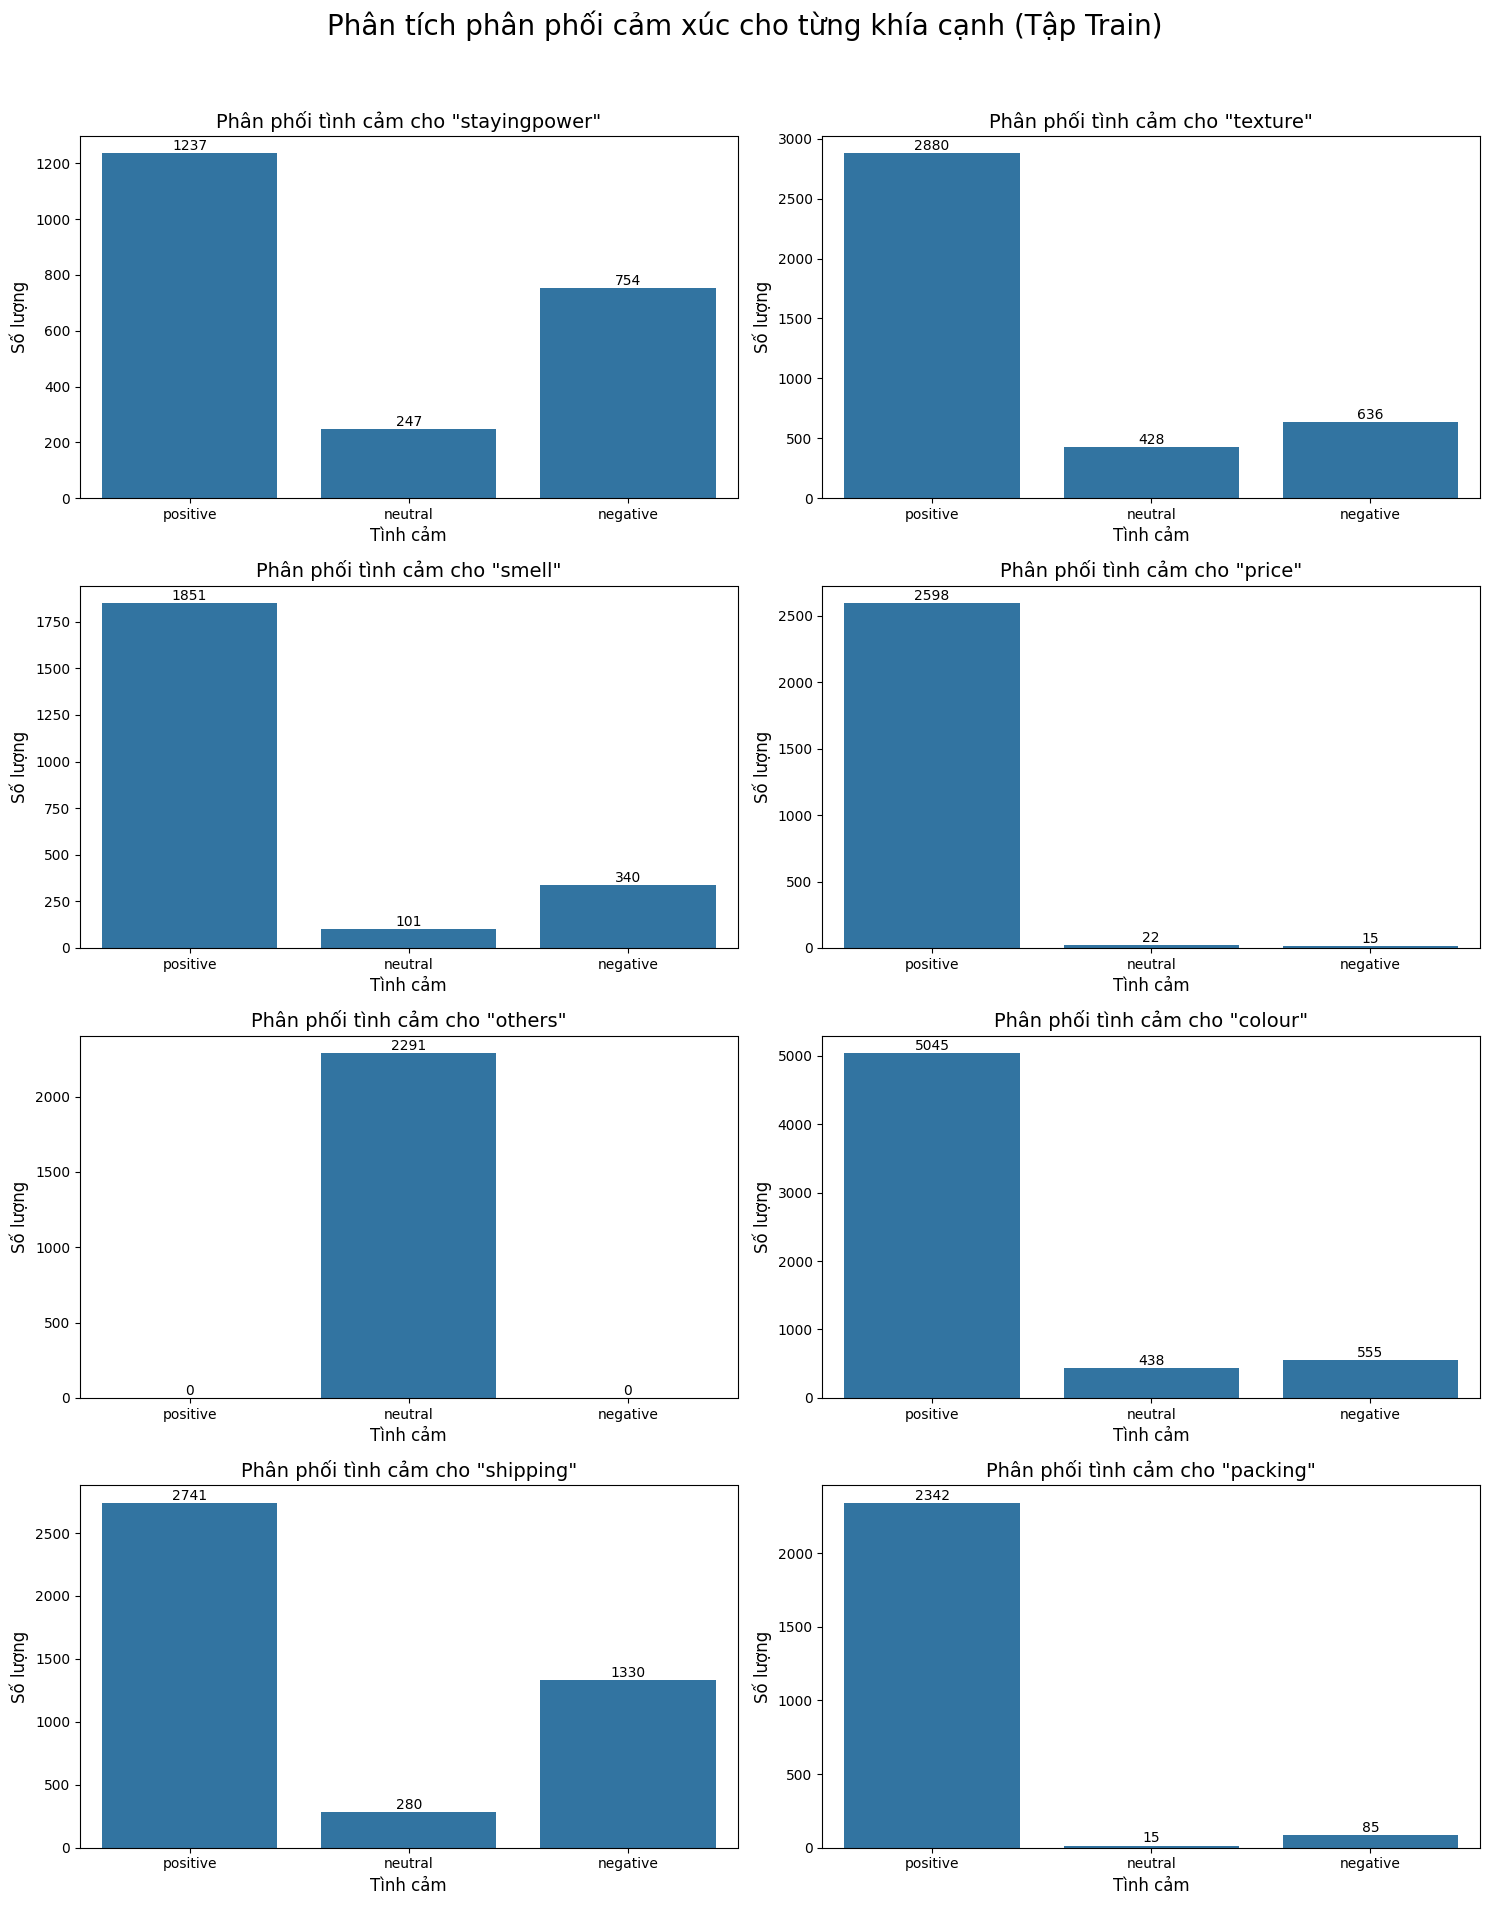

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tải bộ dữ liệu huấn luyện (train)
df_train = pd.read_csv('/content/drive/MyDrive/XlNNTN (TH)/data_train.csv')

# Danh sách các cột khía cạnh cần phân tích
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']

# --- Đếm số lượng tình cảm cho mỗi khía cạnh ---
sentiment_counts = {}
for col in aspect_columns:
    # Đếm số lần xuất hiện của mỗi giá trị (positive, neutral, negative)
    sentiment_counts[col] = df_train[col].value_counts()

# --- Trực quan hóa dữ liệu ---
# Tạo một figure lớn chứa 8 biểu đồ nhỏ (4 hàng, 2 cột)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
fig.suptitle('Phân tích phân phối cảm xúc cho từng khía cạnh (Tập Train)', fontsize=20)

# Làm phẳng mảng axes để dễ dàng lặp qua
axes = axes.flatten()

# Vẽ biểu đồ cột cho từng khía cạnh
for i, col in enumerate(aspect_columns):
    # Lấy dữ liệu đếm của khía cạnh hiện tại
    counts = sentiment_counts[col]

    # Sử dụng seaborn để vẽ biểu đồ cột, sắp xếp theo thứ tự mong muốn
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=['positive', 'neutral', 'negative'])

    # Thiết lập tiêu đề và nhãn cho từng biểu đồ
    axes[i].set_title(f'Phân phối tình cảm cho "{col}"', fontsize=14)
    axes[i].set_xlabel('Tình cảm', fontsize=12)
    axes[i].set_ylabel('Số lượng', fontsize=12)

    # Thêm số lượng trên đỉnh mỗi cột
    # Sắp xếp lại và điền 0 cho các giá trị tình cảm không có để hiển thị đúng
    for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
        axes[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

# Tự động điều chỉnh khoảng cách giữa các biểu đồ con
plt.tight_layout(rect=[0, 0.03, 1, 0.96])

# Lưu biểu đồ thành tệp ảnh
plt.savefig('sentiment_distribution_train.png')

print("Biểu đồ cho tập train đã được lưu vào tệp 'sentiment_distribution_train.png'")

Tập Test


In [ ]:


# Tải tập dữ liệu kiểm tra
df_test = pd.read_csv('/content/drive/MyDrive/XlNNTN (TH)/data_test.csv')

# Hiển thị 5 hàng đầu tiên của tập dữ liệu
print("5 hàng đầu tiên của tập dữ liệu test:")
print(df_test.head())

# Hiển thị thông tin tổng quan về tập dữ liệu (số lượng hàng, cột, kiểu dữ liệu, số lượng giá trị null)
print("\nThông tin tổng quan về tập dữ liệu test:")
df_test.info()

# Hiển thị mô tả thống kê của tập dữ liệu (áp dụng cho các cột số)
print("\nMô tả thống kê của tập dữ liệu test:")
print(df_test.describe())

# Đếm số lượng các giá trị duy nhất trong mỗi cột
print("\nSố lượng giá trị duy nhất trong mỗi cột:")
print(df_test.nunique())

# Hiển thị số lượng các giá trị null trong mỗi cột
print("\nSố lượng giá trị null trong mỗi cột:")
print(df_test.isnull().sum())

5 hàng đầu tiên của tập dữ liệu test:
                                                data stayingpower   texture  \
0  Hàng đóng gói đẹp và chắc chắn, nhìn rất dễ th...          NaN       NaN   
1  Cảm giác son bên trong rất là ít luôn í, đóng ...          NaN       NaN   
2  Son siêu đẹp luôn ý, mà y hình mà chụp có thể ...          NaN  positive   
3  Siu đẹp luôn \r\nShop đóng gói cẩn thận lắm lu...          NaN       NaN   
4  Aúhihđcyihb gfxxth jj bhgfzđE G GHVHBTCEETXUBB...          NaN       NaN   

  smell price   others colour  shipping   packing  
0   NaN   NaN      NaN    NaN       NaN  positive  
1   NaN   NaN      NaN    NaN  positive  positive  
2   NaN   NaN      NaN    NaN       NaN       NaN  
3   NaN   NaN      NaN    NaN       NaN  positive  
4   NaN   NaN  neutral    NaN       NaN       NaN  

Thông tin tổng quan về tập dữ liệu test:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1623 entries, 0 to 1622
Data columns (total 9 columns):
 #   Column        Non-Null

Biểu đồ cho tập test đã được lưu vào tệp 'sentiment_distribution_test.png'


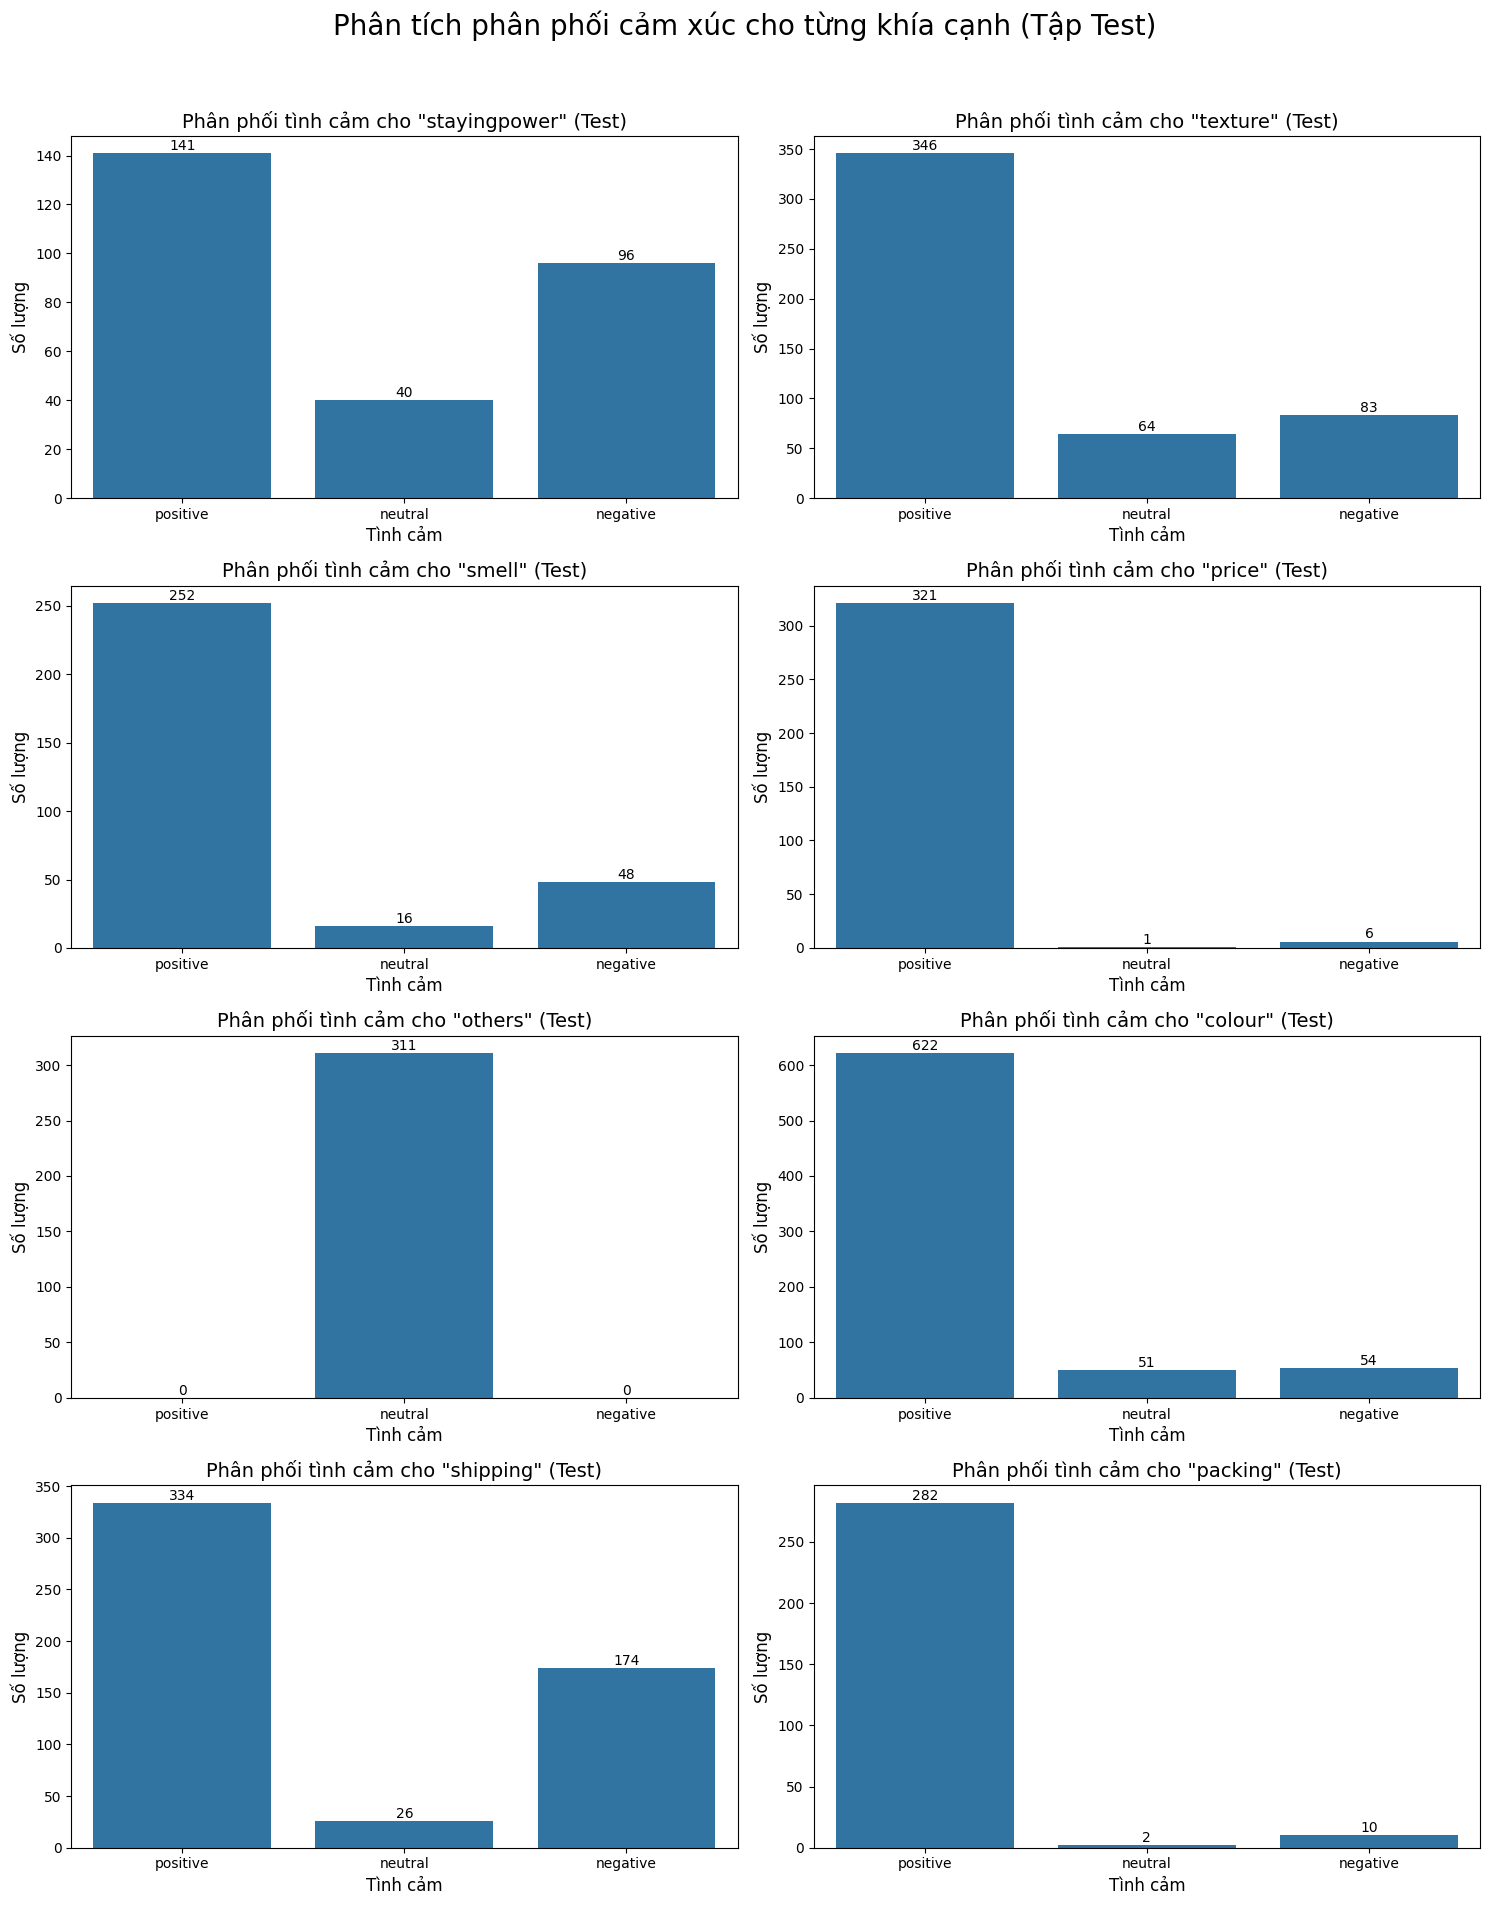

In [ ]:


# Đếm số lượng tình cảm cho mỗi khía cạnh trong tập test
sentiment_counts_test = {}
for col in aspect_columns:
    sentiment_counts_test[col] = df_test[col].value_counts()

# --- Trực quan hóa dữ liệu tập test ---
fig_test, axes_test = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
fig_test.suptitle('Phân tích phân phối cảm xúc cho từng khía cạnh (Tập Test)', fontsize=20)

axes_test = axes_test.flatten()

for i, col in enumerate(aspect_columns):
    counts_test = sentiment_counts_test[col]
    sns.barplot(x=counts_test.index, y=counts_test.values, ax=axes_test[i], order=['positive', 'neutral', 'negative'])
    axes_test[i].set_title(f'Phân phối tình cảm cho "{col}" (Test)', fontsize=14)
    axes_test[i].set_xlabel('Tình cảm', fontsize=12)
    axes_test[i].set_ylabel('Số lượng', fontsize=12)

    for index, value in enumerate(counts_test.reindex(['positive', 'neutral', 'negative']).fillna(0)):
        axes_test[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.savefig('sentiment_distribution_test.png')

print("Biểu đồ cho tập test đã được lưu vào tệp 'sentiment_distribution_test.png'")

tập VAL

In [ ]:
# Tải tập dữ liệu VAl
df_val = pd.read_csv("/content/drive/MyDrive/XlNNTN (TH)/data_val.csv")

# Hiển thị 5 hàng đầu tiên của tập dữ liệu
print("5 hàng đầu tiên của tập dữ liệu validation:")
print(df_val.head())

# Hiển thị thông tin tổng quan về tập dữ liệu (số lượng hàng, cột, kiểu dữ liệu, số lượng giá trị null)
print("\nThông tin tổng quan về tập dữ liệu validation:")
df_val.info()

# Hiển thị mô tả thống kê của tập dữ liệu (áp dụng cho các cột số)
print("\nMô tả thống kê của tập dữ liệu validation:")
print(df_val.describe())

# Đếm số lượng các giá trị duy nhất trong mỗi cột
print("\nSố lượng giá trị duy nhất trong mỗi cột:")
print(df_val.nunique())

# Hiển thị số lượng các giá trị null trong mỗi cột
print("\nSố lượng giá trị null trong mỗi cột:")
print(df_val.isnull().sum())

# Giả sử 'aspect' là cột chứa nhãn lớp (tình cảm)
# Đếm số lượng mẫu cho mỗi lớp trong tập validation
print("\nPhân bố lớp trong tập dữ liệu validation:")
# Kiểm tra xem có cột nào trong aspect_columns tồn tại trong df_val không
# Nếu có, hiển thị phân bố lớp cho cột đó. Nếu không, thông báo không tìm thấy cột lớp.
found_aspect_column = False
for col in aspect_columns:
    if col in df_val.columns:
        print(f"Phân bố cho cột '{col}':")
        print(df_val[col].value_counts())
        found_aspect_column = True
        # Bạn có thể muốn chỉ hiển thị phân bố của một cột hoặc tất cả các cột khía cạnh nếu có.
        # Nếu muốn tất cả, bỏ break.
        # break # Bỏ dòng này nếu muốn hiển thị phân bố cho tất cả các cột khía cạnh
if not found_aspect_column:
    print("Không tìm thấy cột khía cạnh trong tập dữ liệu validation để hiển thị phân bố lớp.")

5 hàng đầu tiên của tập dữ liệu validation:
                                                data stayingpower   texture  \
0  Son màu lên siu đẹp giá lại hạt dẻ, cho shop 5...     negative       NaN   
1  Son mịn lắm á bôi lên thì hơi khô thôi nói chu...          NaN   neutral   
2  Xinh đều màu giao hàng nhanh fjfiidkxsksososxk...          NaN       NaN   
3  Công dụng: Màu siêu xinh luôn nha\nKết cấu: Tô...     positive  positive   
4  Đóng gói hàng cẩn thận. Giao nhanh. Màu son nà...          NaN       NaN   

  smell     price others    colour  shipping   packing  
0   NaN  positive    NaN  positive       NaN       NaN  
1   NaN  positive    NaN       NaN       NaN       NaN  
2   NaN       NaN    NaN  positive  positive       NaN  
3   NaN       NaN    NaN  positive       NaN       NaN  
4   NaN       NaN    NaN  positive  positive  positive  

Thông tin tổng quan về tập dữ liệu validation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1623 entries, 0 to 1622
Data columns (tot

Biểu đồ cho tập validation đã được lưu vào tệp 'sentiment_distribution_val.png'

Phân bố lớp trong tập dữ liệu validation (Chi tiết):

Phân bố cho cột 'stayingpower':
stayingpower
positive    143
negative     90
neutral      31
Name: count, dtype: int64

Phân bố cho cột 'texture':
texture
positive    319
negative     77
neutral      54
Name: count, dtype: int64

Phân bố cho cột 'smell':
smell
positive    238
negative     52
neutral      13
Name: count, dtype: int64

Phân bố cho cột 'price':
price
positive    319
neutral       4
Name: count, dtype: int64

Phân bố cho cột 'others':
others
neutral    270
Name: count, dtype: int64

Phân bố cho cột 'colour':
colour
positive    648
neutral      53
negative     53
Name: count, dtype: int64

Phân bố cho cột 'shipping':
shipping
positive    360
negative    188
neutral      36
Name: count, dtype: int64

Phân bố cho cột 'packing':
packing
positive    309
negative      6
neutral       1
Name: count, dtype: int64


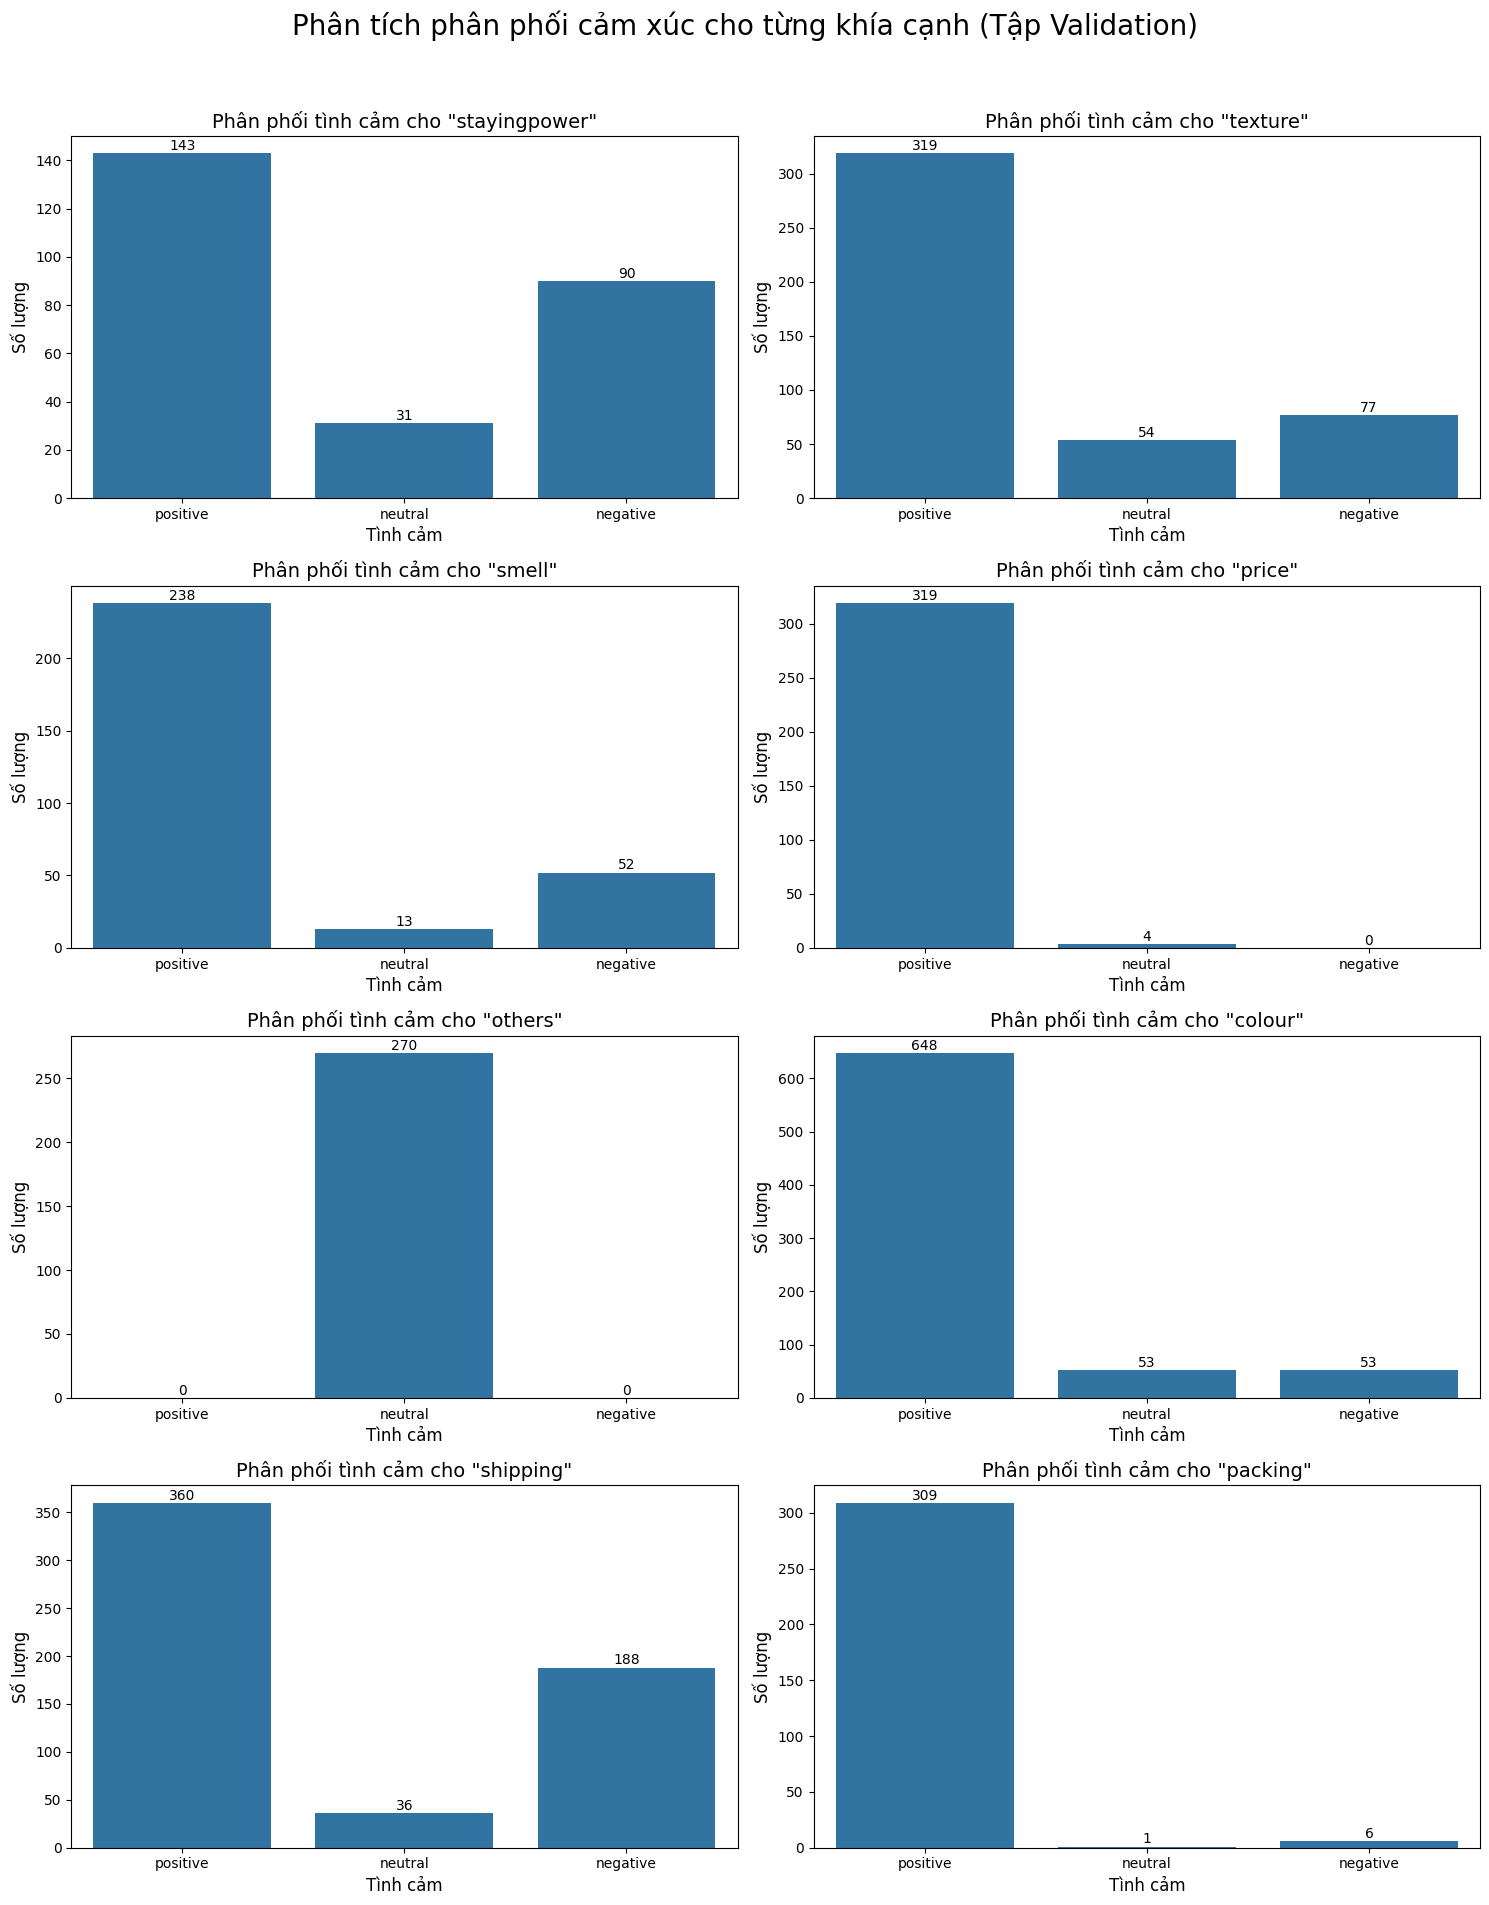

In [ ]:
# Danh sách các cột khía cạnh cần phân tích
aspect_columns = ['stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']

# --- Đếm số lượng tình cảm cho mỗi khía cạnh trong tập VAL ---
sentiment_counts_val = {}
for col in aspect_columns:
    if col in df_val.columns: # Kiểm tra xem cột có tồn tại trong DataFrame không
        # Đếm số lần xuất hiện của mỗi giá trị (positive, neutral, negative)
        sentiment_counts_val[col] = df_val[col].value_counts()
    else:
        print(f"Cột '{col}' không tồn tại trong df_val.")


# --- Trực quan hóa dữ liệu VAL ---
# Chỉ tạo biểu đồ nếu có dữ liệu để vẽ
if sentiment_counts_val:
    num_aspects = len(sentiment_counts_val)
    # Tính toán số hàng và cột cho subplot
    n_cols = 2
    n_rows = (num_aspects + n_cols - 1) // n_cols # Làm tròn lên

    fig_val, axes_val = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, n_rows * 5))
    fig_val.suptitle('Phân tích phân phối cảm xúc cho từng khía cạnh (Tập Validation)', fontsize=20)

    # Làm phẳng mảng axes để dễ dàng lặp qua
    axes_val = axes_val.flatten()

    # Vẽ biểu đồ cột cho từng khía cạnh có dữ liệu trong tập VAL
    for i, col in enumerate(sentiment_counts_val.keys()):
        # Lấy dữ liệu đếm của khía cạnh hiện tại
        counts = sentiment_counts_val[col]

        # Sử dụng seaborn để vẽ biểu đồ cột, sắp xếp theo thứ tự mong muốn
        sns.barplot(x=counts.index, y=counts.values, ax=axes_val[i], order=['positive', 'neutral', 'negative'])

        # Thiết lập tiêu đề và nhãn cho từng biểu đồ
        axes_val[i].set_title(f'Phân phối tình cảm cho "{col}"', fontsize=14)
        axes_val[i].set_xlabel('Tình cảm', fontsize=12)
        axes_val[i].set_ylabel('Số lượng', fontsize=12)

        # Thêm số lượng trên đỉnh mỗi cột
        # Sắp xếp lại và điền 0 cho các giá trị tình cảm không có để hiển thị đúng
        for index, value in enumerate(counts.reindex(['positive', 'neutral', 'negative']).fillna(0)):
             axes_val[i].text(index, value + 0.1, str(int(value)), ha='center', va='bottom')

    # Ẩn các subplot không sử dụng nếu số lượng khía cạnh lẻ
    for j in range(i + 1, len(axes_val)):
        fig_val.delaxes(axes_val[j])


    # Tự động điều chỉnh khoảng cách giữa các biểu đồ con
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])

    # Lưu biểu đồ thành tệp ảnh
    plt.savefig('sentiment_distribution_val.png')

    print("Biểu đồ cho tập validation đã được lưu vào tệp 'sentiment_distribution_val.png'")
else:
    print("Không có dữ liệu khía cạnh nào được tìm thấy trong df_val để trực quan hóa.")

# In phân bố lớp cho từng cột khía cạnh trong tập validation
print("\nPhân bố lớp trong tập dữ liệu validation (Chi tiết):")
for col in aspect_columns:
    if col in df_val.columns:
        print(f"\nPhân bố cho cột '{col}':")
        print(df_val[col].value_counts())
    else:
        print(f"\nCột '{col}' không tồn tại trong df_val.")